# AG's news corpus (newsSpace): dates, ordering and the two crawl eras

This notebook summarises the exploratory analysis of `raw_newsspace.csv`: the whole MySQL dump `newsSpace`, one
row per article, 9 columns, NULL written as `\N`. Create it with `python prepare_newsspace.py --raw raw_newsspace.csv`.

* **Part 1: the whole dataset.** Where the missing dates are, how far the rows are from chronological order,
  whether time zones play a role, what the dates inside URLs are worth, and estimates for the missing dates. The
  file splits into an older part (*era A*, 2004–2005, about 69% of rows undated) and a newer, fully dated part
  (*era B*, 2006–2008), and Part 1 ends by comparing their sources.
* **Part 2: era B only.** Era A is left out because its dates are not reliable. Era B is profiled column by column.

`row` is always the 0-based position of a record in the file, which is the order of the MySQL dump.

Requirements: pandas, numpy and matplotlib. The data takes about 3 GB of RAM, and the whole notebook runs in about a minute.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})

RAW_CSV = 'raw_newsspace.csv'   # made by prepare_newsspace.py --raw; NULL is stored as \N

## Part 1: the whole dataset

### 1.1 Loading, NULLs and placeholders

The raw CSV keeps MySQL NULLs as `\N`. So every column is read as text and only `\N` becomes NaN. With
`keep_default_na=False`, strings such as `none` or `NA` stay as real values. `pubdate = 0000-00-00 00:00:00` is
MySQL's *zero date*, which means "unknown", so it becomes `NaT`.

In [2]:
df = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False, na_values=[r'\N'])
df['row'] = np.arange(len(df))
df['rank'] = df['rank'].astype(int)
zero_date = df['pubdate'].eq('0000-00-00 00:00:00')
df['ts'] = pd.to_datetime(df['pubdate'].mask(zero_date), format='%Y-%m-%d %H:%M:%S')
df['has_date'] = df['ts'].notna()

print(f"{len(df):,} rows: {df['has_date'].sum():,} with a date, {(~df['has_date']).sum():,} without "
      f"({(~df['has_date']).mean():.1%})")
df.head(3)

1,281,103 rows: 871,894 with a date, 409,209 without (31.9%)


,source,url,title,image,category,description,rank,pubdate,video,row,ts,has_date
0,Yahoo Business,http://us.rd.yahoo.com/dailynews/rss/business/*http://story.news.yahoo.com/news?tmpl=s...,Wall St. Pullback Reflects Tech Blowout (Reuters),none,Business,"Reuters - Wall Street's long-playing drama,\n""Waiting for Google,"" is about to reach i...",5,0000-00-00 00:00:00,NaN,0,NaT,False
1,Yahoo Business,http://us.rd.yahoo.com/dailynews/rss/business/*http://story.news.yahoo.com/news?tmpl=s...,Wall St. Bears Claw Back Into the Black (Reuters),none,Business,"Reuters - Short-sellers, Wall Street's dwindling\nband of ultra-cynics, are seeing gre...",5,0000-00-00 00:00:00,NaN,1,NaT,False
2,Yahoo Business,http://us.rd.yahoo.com/dailynews/rss/business/*http://story.news.yahoo.com/news?tmpl=s...,Carlyle Looks Toward Commercial Aerospace (Reuters),none,Business,"Reuters - Private investment firm Carlyle Group,\nwhich has a reputation for making we...",5,0000-00-00 00:00:00,NaN,2,NaT,False


In [3]:
cols = ['source', 'url', 'title', 'image', 'category', 'description', 'rank', 'pubdate', 'video']
null_table = pd.DataFrame({
    r'NULL (\N)': df[cols].isna().sum(),
    "empty string ''": pd.Series({c: df[c].eq('').sum() for c in cols}),
    "placeholder value": pd.Series({'pubdate': zero_date.sum(), 'image': df['image'].eq('none').sum()}),
}).fillna(0).astype(int)
null_table

,NULL (\N),empty string '',placeholder value
category,0,0,0
description,27334,11,0
image,0,300128,560478
pubdate,0,0,409209
rank,0,0,0
source,0,0,0
title,0,0,0
url,0,0,0
video,1281103,0,0


* `video` is NULL in every row, so the column is unused.
* `description` is NULL in 27,334 rows, and 11 more are empty strings.
* `pubdate` holds the zero date ("unknown") in 409,209 rows, about 32% of the file. It is never a real NULL.
* `image` marks "no image" in two ways, `'none'` and `''`. The empty string is used only in era A.

### 1.2 Where are the missing dates?

The share of undated rows is plotted along the file, in blocks of 10,000 rows. The last undated row is the
boundary between the two eras.

era A: rows         0 –   594,726  (  594,727 rows)   undated  68.8%   dates 2004-08-17 – 2005-02-17
era B: rows   594,727 – 1,281,102  (  686,376 rows)   undated   0.0%   dates 2006-05-19 – 2008-02-20


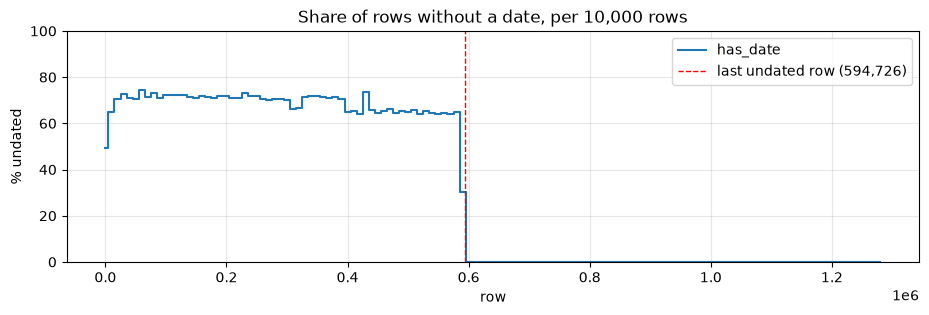

In [4]:
BOUNDARY = int(df.loc[~df['has_date'], 'row'].max())          # last row without a date
df['era'] = np.where(df['row'] <= BOUNDARY, 'A', 'B')
in_a = df['era'].eq('A')

for era, g in df.groupby('era'):
    print(f"era {era}: rows {g['row'].min():>9,} – {g['row'].max():>9,}  ({len(g):>9,} rows)   "
          f"undated {(~g['has_date']).mean():6.1%}   dates {g['ts'].min():%Y-%m-%d} – {g['ts'].max():%Y-%m-%d}")

undated_share = (~df['has_date']).groupby(df['row'] // 10_000).mean().mul(100)
undated_share.index = undated_share.index * 10_000
ax = undated_share.plot(figsize=(11, 3), drawstyle='steps-mid')
ax.axvline(BOUNDARY, color='red', ls='--', lw=1, label=f'last undated row ({BOUNDARY:,})')
ax.set(xlabel='row', ylabel='% undated', title='Share of rows without a date, per 10,000 rows', ylim=(0, 100))
ax.legend()
plt.show()

Every undated row is in the first 594,727 rows, rows 0 to 594,726. Inside that part, about 70% of rows have no
date, and the share stays fairly flat along the whole part. After the boundary, every row has a date. The boundary
is not only a change in missing data. Section 1.9 shows that the set of sources changes there too.

### 1.3 Dates against file position

Each dot is one dated row (a random sample of 200,000). If the file were sorted by date, the dots would form one
rising line.

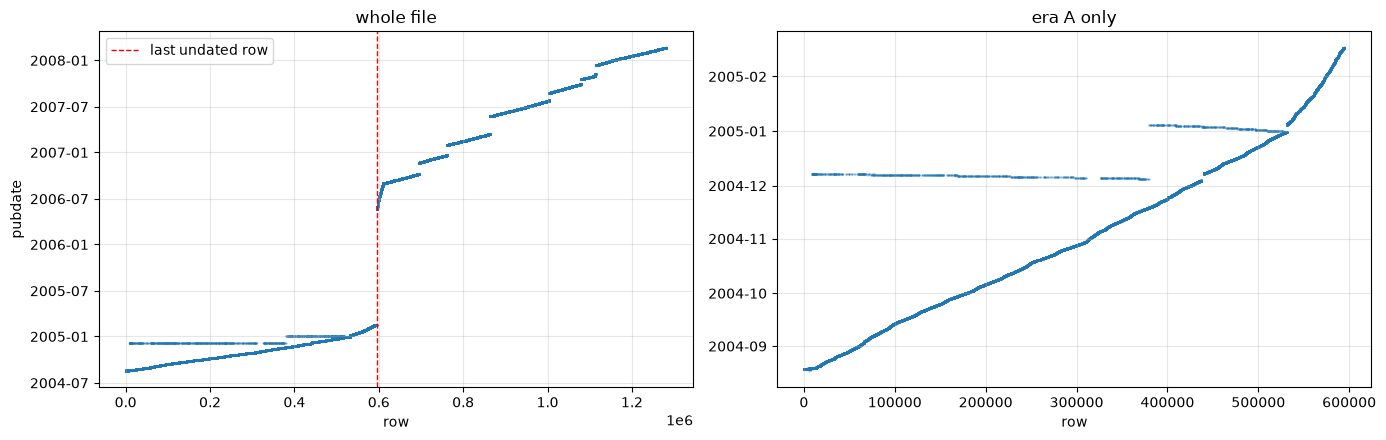

no dated row between 2005-02-17 10:30:45 (last in era A) and 2006-05-19 12:56:51 (first in era B): 456 days


In [5]:
dated = df[df['has_date']]
sample = dated.sample(200_000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(sample['row'], sample['ts'], s=0.3, alpha=0.3)
axes[0].axvline(BOUNDARY, color='red', ls='--', lw=1, label='last undated row')
axes[0].set(title='whole file', xlabel='row', ylabel='pubdate')
axes[0].legend(loc='upper left')
a_sample = sample[sample['era'].eq('A')]
axes[1].scatter(a_sample['row'], a_sample['ts'], s=0.5, alpha=0.3)
axes[1].set(title='era A only', xlabel='row')
fig.tight_layout()
plt.show()

gap_start, gap_end = df.loc[in_a, 'ts'].max(), df.loc[~in_a, 'ts'].min()
print(f'no dated row between {gap_start} (last in era A) and {gap_end} (first in era B): '
      f'{(gap_end - gap_start).days} days')

* The file is **broadly chronological**: the dots rise from left to right.
* Between the eras there is a **gap of about 15 months**, Feb 2005 to May 2006, with no dated row at all.
* Era A has **two horizontal stripes**. Rows dated about 5–7 Dec 2004 are scattered thinly from row ~9,000 to row
  ~380,000, among August–November rows. Rows dated around New Year 2005 are scattered from row ~380,000 to row
  ~530,000. Section 1.7 looks at them.
* Era B's line has **jumps**. Those are periods when nothing was collected; the next cell lists them.

In [6]:
s = df['ts'].dropna().sort_values().reset_index(drop=True)
gap = s.diff()
idx = gap[gap > pd.Timedelta(days=3)].index
outages = pd.DataFrame({'last date before': s[idx - 1].values, 'first date after': s[idx].values,
                        'gap': gap[idx].dt.round('h').values}).sort_values('last date before', ignore_index=True)
outages['era'] = np.where(outages['last date before'] < df.loc[~in_a, 'ts'].min(), 'A→B', 'B')
display(outages)
b = outages[outages['era'].eq('B')]
span = df.loc[~in_a, 'ts'].max() - df.loc[~in_a, 'ts'].min()
print(f"era B spans {span.days} days, of which {b['gap'].sum().days} days ({b['gap'].sum() / span:.0%}) are outages")

,last date before,first date after,gap,era
0,2005-02-17 10:30:45,2006-05-19 12:56:51,456 days 02:00:00,A→B
1,2006-06-02 06:11:06,2006-06-15 09:32:08,13 days 03:00:00,B
2,2006-10-08 16:10:00,2006-11-21 16:02:54,44 days 00:00:00,B
3,2006-12-20 12:12:31,2007-01-30 19:37:58,41 days 07:00:00,B
4,2007-03-14 20:49:44,2007-05-24 12:06:37,70 days 15:00:00,B
5,2007-07-26 05:57:05,2007-08-24 13:19:40,29 days 07:00:00,B
6,2007-09-29 00:14:59,2007-10-18 12:08:21,19 days 12:00:00,B
7,2007-11-04 06:30:40,2007-11-08 09:51:38,4 days 03:00:00,B
8,2007-11-08 13:44:41,2007-12-13 11:00:41,34 days 21:00:00,B


era B spans 642 days, of which 256 days (40%) are outages


Era A has no break longer than about a day and a half. Era B is collected in bursts: it has seven outages of 2 to
10 weeks, plus one of 4 days. Together they cover about 40% of its nominal span. Any per-month count in era B has to
take them into account.

### 1.4 Partial shuffling

This section measures how far the dated rows are from sorted order. Three measures are used:

* **steps backwards:** how often a dated row has an earlier timestamp than the dated row before it.
* **lag behind the running maximum:** how far a row's date is behind the latest date seen so far in the file.
* **deviation from the local clock:** each row is compared with the median timestamp of the 2,000 dated rows
  around it. That median is the "crawl clock" at that point of the file.

In [7]:
def order_stats(g):
    step = g['ts'].diff().dropna()
    lag = g['ts'].cummax() - g['ts']
    return pd.Series({
        'dated rows': f'{len(g):,}',
        'steps backwards': f"{(step < pd.Timedelta(0)).mean():.1%}",
        'steps back by more than 1 day': f"{(step < -pd.Timedelta(days=1)).sum():,}",
        'largest step back': str(-step.min()),
        'lag behind running max: median': str(lag.median().round('min')),
        'lag behind running max: 99th percentile': str(lag.quantile(0.99).round('min')),
        'lag behind running max: maximum': str(lag.max().round('min')),
    })

d = df.loc[df['has_date'], ['row', 'era', 'source', 'ts']].copy()
d.groupby('era').apply(order_stats).T

era,A,B
dated rows,"185,518","686,376"
steps backwards,47.2%,49.5%
steps back by more than 1 day,"5,067",0
largest step back,110 days 10:14:30,0 days 03:19:06
lag behind running max: median,38 days 11:11:00,0 days 01:11:00
lag behind running max: 99th percentile,110 days 01:12:00,0 days 02:38:00
lag behind running max: maximum,110 days 19:14:00,0 days 03:42:00


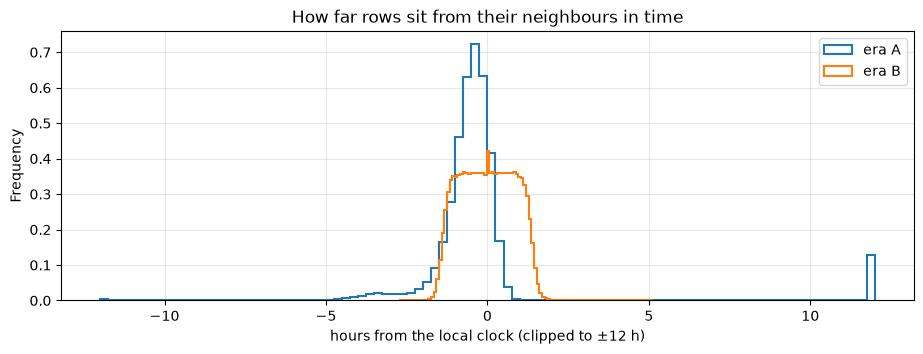

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
era,,,,,,,,,,,,
A,185518.0,39.51,261.21,-93.62,-3.97,-2.01,-0.87,-0.46,-0.10,0.46,1699.02,2649.72
B,686376.0,0.00,0.82,-2.72,-1.48,-1.27,-0.69,0.00,0.69,1.27,1.50,5.12


In [8]:
EPOCH = pd.Timestamp('2000-01-01')
secs = (d['ts'] - EPOCH).dt.total_seconds()
clock = secs.rolling(2001, center=True, min_periods=101).median()
d['clock'] = EPOCH + pd.to_timedelta(clock, unit='s')       # median date of the ~2,000 surrounding dated rows
d['dev_h'] = (secs - clock) / 3600                          # + = later than its neighbours, - = earlier

fig, ax = plt.subplots(figsize=(11, 3.5))
for era, g in d.groupby('era'):
    g['dev_h'].clip(-12, 12).plot.hist(bins=96, density=True, histtype='step', lw=1.5, ax=ax, label=f'era {era}')
ax.set(xlabel='hours from the local clock (clipped to ±12 h)', title='How far rows sit from their neighbours in time')
ax.legend()
plt.show()

d.groupby('era')['dev_h'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2)

* **Era B is ordered by day.** There is no step backwards of more than a day. About half of the neighbouring pairs
  are still swapped by minutes or hours, and most rows sit within about ±1.5 hours of their neighbours. So the
  order holds by day but is shuffled within the day.
* **Era A is ordered only roughly.** Most rows are also within an hour or two of their neighbours. But a minority
  sit days or months away, which gives the long tails and steps back of up to about 110 days. Those are the
  stripes in 1.3. The median lag behind the running maximum, 38 days, is misleading. By row ~9,100 the running
  maximum has already jumped to 7 December, so every normally placed row after it "lags". The deviation from the
  local clock is the more useful measure here.
* So a strict date order needs an explicit sort. File order is only an approximation.

### 1.5 Dates hidden in URLs

Many news URLs contain the publication date. Four patterns are tried in order, and the first valid date between
2000 and 2009 is kept:

| pattern | example |
|---|---|
| `/YYYY/MM_Month/DD/` | Corriere `/2004/08_Agosto/16/` |
| `/YYYY/M/D/` | `/2004/8/13/`, `/2004/08/13/` |
| `YYYY-MM-DD` | `2004-12/07`, `2004-08-13` |
| `YYYYMMDD` | Yahoo `/nm/20040814/` |

In [9]:
URL_PATTERNS = {
    '/YYYY/MM_Month/DD/': r'/(20\d\d)/(\d\d)_[A-Za-z]+/(\d{1,2})/',
    '/YYYY/M/D/':         r'/(20\d\d)/(\d{1,2})/(\d{1,2})(?:/|$)',
    'YYYY-MM-DD':         r'(?<!\d)(20\d\d)[-_./](\d\d)[-_./](\d\d)(?!\d)',
    'YYYYMMDD':           r'(?<!\d)(20\d\d)(\d\d)(\d\d)(?!\d)',
}
url_date = pd.Series(pd.NaT, index=df.index, dtype='datetime64[s]')
url_pattern = pd.Series(None, index=df.index, dtype=object)
for name, pat in URL_PATTERNS.items():
    m = df['url'].str.extract(pat)
    found = pd.to_datetime(m[0] + '-' + m[1].str.zfill(2) + '-' + m[2].str.zfill(2),
                           format='%Y-%m-%d', errors='coerce')
    found = found.where(found.dt.year.between(2000, 2009))
    new = url_date.isna() & found.notna()
    url_date[new] = found[new]
    url_pattern[new] = name

df['url_date'] = url_date
df['url_pattern'] = url_pattern
df['url_day_diff'] = (df['url_date'] - df['ts'].dt.normalize()).dt.days   # URL date minus pubdate day

coverage = df.groupby(['era', 'has_date'])['url_date'].agg(rows='size', with_url_date='count')
coverage['share'] = (coverage['with_url_date'] / coverage['rows']).map('{:.1%}'.format)
display(coverage)
display(df['url_pattern'].value_counts().rename('rows with a URL date, by pattern').to_frame())

rows  with_url_date  share
era has_date                              
A   False     409209         146100  35.7%
    True      185518          63263  34.1%
B   True      686376         398469  58.1%

,"rows with a URL date, by pattern"
url_pattern,
YYYYMMDD,241064
YYYY-MM-DD,187856
/YYYY/M/D/,177772
/YYYY/MM_Month/DD/,1140


In [10]:
v = df[df['has_date'] & df['url_date'].notna()]
bucket = pd.cut(v['url_day_diff'].abs(), [-1, 0, 1, 7, 60, np.inf],
                labels=['same day', '±1 day', '2–7 days', '8–60 days', '>60 days'])
acc = pd.crosstab([v['era'], v['url_pattern']], bucket, normalize='index').mul(100).round(1)
acc.insert(0, 'rows', v.groupby(['era', 'url_pattern']).size())
print('Accuracy of the URL date against pubdate (dated rows), % of rows')
display(acc)

signed = v['url_day_diff'].clip(-5, 5).value_counts(normalize=True).sort_index().mul(100).round(1)
signed.index = [f'{int(i):+d}' + (' or more' if abs(i) == 5 else '') for i in signed.index]
print('URL date minus pubdate (days), % of rows')
display(signed.to_frame('%').T)

Accuracy of the URL date against pubdate (dated rows), % of rows


url_day_diff              rows  same day  ±1 day  2–7 days  8–60 days  >60 days
era url_pattern                                                                
A   /YYYY/M/D/           22892      51.7    32.4      15.0        0.9       0.1
    /YYYY/MM_Month/DD/     402      51.5    34.6      13.9        0.0       0.0
    YYYY-MM-DD           14574      45.8    35.4      18.6        0.1       0.1
    YYYYMMDD             25395      64.1    25.9       9.2        0.8       0.0
B   /YYYY/M/D/          108120      66.6    23.2       7.5        2.4       0.3
    YYYY-MM-DD          146205      88.4    11.3       0.1        0.2       0.0
    YYYYMMDD            144144      81.9    17.1       1.0        0.0       0.0

URL date minus pubdate (days), % of rows


,-5 or more,-4,-3,-2,-1,+0,+1,+2,+3,+4,+5 or more
%,1.3,0.4,1.1,1.9,18.0,76.7,0.5,0.0,0.0,0.0,0.0


* **Era B:** the URL date matches pubdate on the same day for 67–88% of rows, depending on the pattern, and within
  ±1 day for 90–99%.
* **Era A:** the match is much weaker. 46–64% fall on the same day and 9–19% are 2–7 days off. In era A, pubdate
  looks more like the moment the crawler saw an article than the moment it was published.
* **Direction:** when the two differ, the URL date is almost always *earlier* than pubdate. The URL carries the
  publication date, and pubdate comes later, either by time zone (1.6) or by crawl delay.

### 1.6 Time zones

The hypothesis: the crawler ran in Italy, while many sources are American, and each site may handle time zones
differently.

Two consequences can be tested:

1. **If sites' timestamps were stored in their own local time**, each source would sit at its own fixed offset from
   the crawl clock. A US source would sit 6–9 hours behind, and the offsets would cluster at whole hours.
2. **If all timestamps are on one clock** that runs ahead of US time, a US evening article would get an
   after-midnight timestamp on the next day. Its URL would then show the day before pubdate, and pubdate would be
   just after midnight.

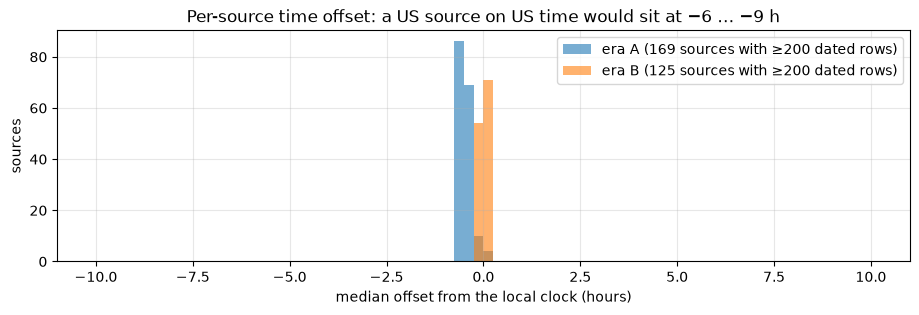

largest era-B sources:


,era,rows,median_offset_h,iqr_h
source,,,,
Reuters Top News,B,30409,0.00,1.37
Yahoo World,B,24723,0.00,1.35
Yahoo Europe,B,21997,-0.01,1.38
Yahoo Entertainment,B,21224,0.00,1.37
Kataweb Sport,B,20849,-0.02,1.38
BBC - Front Page,B,18935,0.01,1.39
BBC UK,B,18717,-0.00,1.37
Reuters Business,B,18448,0.01,1.39
Reuters World,B,18442,-0.01,1.38


In [11]:
iqr = lambda s: s.quantile(0.75) - s.quantile(0.25)
per_src = d.groupby(['era', 'source'])['dev_h'].agg(rows='size', median_offset_h='median', iqr_h=iqr)
big = per_src[per_src['rows'] >= 200].reset_index()

fig, ax = plt.subplots(figsize=(11, 3))
for era, g in big.groupby('era'):
    g['median_offset_h'].plot.hist(bins=np.arange(-10, 10.25, 0.25), alpha=0.6, ax=ax,
                                    label=f'era {era} ({len(g)} sources with ≥200 dated rows)')
ax.set(xlabel='median offset from the local clock (hours)', ylabel='sources',
       title='Per-source time offset: a US source on US time would sit at −6 … −9 h')
ax.legend()
plt.show()

print('largest era-B sources:')
display(big[big['era'].eq('B')].nlargest(12, 'rows').round(2).set_index('source'))

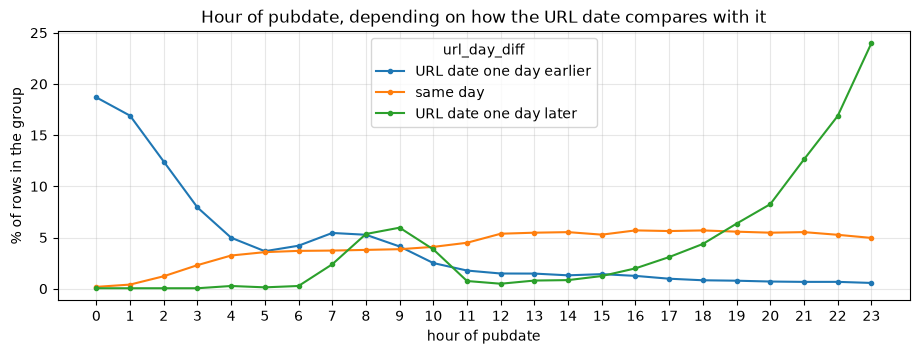

url_day_diff,rows,URL date one day earlier,same day,URL date one day later,median pubdate hour when URL is a day earlier
source group,,,,,
Italian,58403,7.1,92.9,0.0,1.0
NYT / Boston Globe,67864,9.3,87.4,3.2,7.0
"US (Yahoo, WaPo, CNN, …)",187504,25.1,74.9,0.0,3.0
other,126025,20.4,79.6,0.1,3.0


In [12]:
v = df[df['has_date'] & df['url_day_diff'].between(-1, 1)].copy()
labels = {-1: 'URL date one day earlier', 0: 'same day', 1: 'URL date one day later'}
hours = pd.crosstab(v['ts'].dt.hour, v['url_day_diff'], normalize='columns').mul(100).rename(columns=labels)
ax = hours.plot(figsize=(11, 3.5), marker='o', ms=3)
ax.set(xlabel='hour of pubdate', ylabel='% of rows in the group', xticks=range(24),
       title='Hour of pubdate, depending on how the URL date compares with it')
plt.show()

IT = r"\bAnsa\b|Corriere|Repubblica|Kataweb|L'Unit|Gazzetta|Sole 24|La Stampa|L'Espresso|\bRai\b|Tgcom|Messaggero|Panorama"
US = r'^(?:Yahoo|The Washington Post|Washington Post|CNN|ABC News|San Francisco|Reuters U\.S\.|Forbes|USA Today)'
NYT = r'New York Times|Boston Globe'
v['source group'] = np.select([v['source'].str.contains(NYT), v['source'].str.contains(IT), v['source'].str.contains(US)],
                              ['NYT / Boston Globe', 'Italian', 'US (Yahoo, WaPo, CNN, …)'], 'other')
tz = pd.crosstab(v['source group'], v['url_day_diff'], normalize='index').mul(100).round(1).rename(columns=labels)
tz.insert(0, 'rows', v['source group'].value_counts())
tz['median pubdate hour when URL is a day earlier'] = (
    v[v['url_day_diff'].eq(-1)].groupby('source group')['ts'].apply(lambda s: s.dt.hour.median()))
tz

**The time-zone theory is half right.**

* **Not per site.** Every large source sits at the same offset from its neighbours, about 0 h in era B. No source
  is at −6 … −9 h, so sites were *not* stored in their own local time. The shuffling inside a day is the same for
  every source, so it comes from how rows were stored or exported, not from time zones. In era A the whole
  distribution shifts by about −0.5 h, because the misplaced rows (1.7) pull the local median up. It is still one
  peak, not one per time zone.
* **One common clock, ahead of US time.** When the URL date is a day earlier than pubdate, pubdate is usually
  between 00:00 and 03:00. US sources are off by a day about 25% of the time. Italian sources are off only about
  7% of the time, and then at around 01:00. That fits a single server clock on European (Italian) time, or UTC; the
  data cannot tell the two apart. US evening articles get timestamps after midnight on that clock.
* **NYT and Boston Globe** are almost the only sources where the URL date is sometimes a day *later* (about 3% of
  their rows), with pubdate mostly at 20:00–23:00. That is a site convention: their URLs carry the next morning's
  print-edition date.

### 1.7 Misplaced rows in era A

These are the dated rows in era A that sit more than 2 days away from the local clock.

In [13]:
a = d[d['era'].eq('A')].join(df[['url_date', 'url']])
far = a[a['dev_h'].abs() > 48]
ahead = far[far['dev_h'] > 0]
print(f"{len(far):,} of {len(a):,} dated era-A rows ({len(far) / len(a):.1%}) are more than 2 days from their "
      f"neighbours: {len(ahead):,} ahead, {len(far) - len(ahead):,} behind")

print('\nmost common dates carried by the rows that are ahead:')
display(ahead['ts'].dt.date.value_counts().head(10).rename('rows').to_frame().T)

chk = ahead[ahead['url_date'].notna()]
agree = ((chk['url_date'] - chk['ts'].dt.normalize()).dt.days.abs() <= 1).mean()
print(f'{len(chk):,} of them have a URL date, and it agrees with pubdate (±1 day) for {agree:.0%}')
ahead.assign(clock=ahead['clock'].dt.floor('min'))[['row', 'ts', 'clock', 'url_date', 'source', 'url']].head(8)

5,769 of 185,518 dated era-A rows (3.1%) are more than 2 days from their neighbours: 5,740 ahead, 29 behind

most common dates carried by the rows that are ahead:


ts,2004-12-07,2004-12-06,2004-12-05,2005-01-03,2005-01-04,2005-01-01,2005-01-02,2004-12-31
rows,1638,1280,1032,605,406,368,344,67


2,122 of them have a URL date, and it agrees with pubdate (±1 day) for 89%


,row,ts,clock,url_date,source,url
9100,9100,2004-12-07 20:53:15,2004-08-19 11:28:00,2004-12-07,Yahoo World,http://us.rd.yahoo.com/dailynews/rss/world/*http://story.news.yahoo.com/news?tmpl=stor...
9105,9105,2004-12-07 20:37:36,2004-08-19 11:28:00,NaT,This is London,http://news.bbc.co.uk/2/hi/entertainment/4074741.stm
9107,9107,2004-12-07 20:54:35,2004-08-19 11:28:00,NaT,Bloomberg,http://www.ecommercetimes.com/story/wallst/oil-opec-supply-38687.html
9121,9121,2004-12-07 20:47:57,2004-08-19 11:29:00,NaT,Xposed.com,http://www.cbc.ca/cp/world/041207/w120734.html
9166,9166,2004-12-07 20:25:59,2004-08-19 11:31:00,2004-12-07,Christian Science Monitor,http://www.chinadaily.com.cn/english/doc/2004-12/07/content_397867.htm
9172,9172,2004-12-07 21:02:18,2004-08-19 11:31:00,NaT,TechNewsWorld,http://www.crmbuyer.com/story/Cisco-Fujitsu-Ally-on-Router-Sales-in-Asia-38740.html
9175,9175,2004-12-07 21:14:35,2004-08-19 11:31:00,NaT,Reuters,http://www.sudantribune.com/article.php3?id_article=6863
9196,9196,2004-12-07 21:04:01,2004-08-19 11:32:00,2004-12-06,Reuters,http://news.xinhuanet.com/english/2004-12/06/content_2301877.htm


These rows carry **genuine** dates, which their URLs confirm, but they sit in the wrong place in the file. They come
from two short periods, **5–7 Dec 2004** and **31 Dec 2004 – 4 Jan 2005**. Each period is scattered thinly over
hundreds of thousands of older rows: from row ~9,100 to ~380,000, and from ~380,000 to ~530,000. So in era A, file
order is *not* the order in which rows were inserted.

A likely mechanism, not verified: a MySQL MyISAM table reuses the space of deleted rows for new inserts, and a dump
follows the physical order. After a large deletion, the next few days of inserts would fill the holes spread over
the file, which is exactly this picture.

This matters for estimating missing dates from neighbouring rows: next to one of these rows, a neighbour's date can
be months off.

### 1.8 Estimating the missing dates

The estimate combines two sources:

1. **URL date from a validated source.** A source counts as validated if, on its dated rows (at least 20 with a URL
   date), the URL date is within ±1 day of pubdate in at least 90% of cases.
2. **Same-source neighbours.** Otherwise, the estimate is the midpoint between the previous and the next dated row
   of the same source in file order. The distance between those two rows ("bracket width") shows how certain the
   estimate is.

In [14]:
v = df[df['has_date'] & df['url_date'].notna()]
rel = (v['url_day_diff'].abs() <= 1).groupby(v['source']).agg(['size', 'mean'])
reliable = rel.index[(rel['size'] >= 20) & (rel['mean'] >= 0.9)]
print(f"validated URL-date sources: {len(reliable)} of {(rel['size'] >= 20).sum()} sources with ≥20 checkable rows")

undated = ~df['has_date']
by_src = df.groupby('source')['ts']
nb = pd.concat([by_src.ffill(), by_src.bfill()], axis=1)     # previous / next dated row of the same source
lo, hi = nb.min(axis=1), nb.max(axis=1)
mid = lo + (hi - lo) / 2
use_url = undated & df['url_date'].notna() & df['source'].isin(reliable)

df['date_estimate'] = df['ts'].where(df['has_date'], mid).where(~use_url, df['url_date'])
df['estimate_method'] = np.select([df['has_date'], use_url, undated & mid.notna()],
                                  ['real pubdate', 'URL date (validated source)', 'same-source neighbours'],
                                  'no estimate')
bracket_days = ((hi - lo).dt.total_seconds() / 86400).where(df['estimate_method'].eq('same-source neighbours'))

display(df.loc[undated, 'estimate_method'].value_counts().rename('undated rows').to_frame())
display(pd.cut(bracket_days.dropna(), [-0.01, 1, 7, 30, np.inf], labels=['≤ 1 day', '1–7 days', '7–30 days', '> 30 days'])
          .value_counts(sort=False).rename('neighbour-based estimates, by bracket width').to_frame())

validated URL-date sources: 63 of 295 sources with ≥20 checkable rows


,undated rows
estimate_method,
same-source neighbours,323492
URL date (validated source),84293
no estimate,1424


,"neighbour-based estimates, by bracket width"
≤ 1 day,222977
1–7 days,59020
7–30 days,20799
> 30 days,20696


In [15]:
win = df['row'] // 50_000
und_url = in_a & undated & df['url_date'].notna()
dat_a = in_a & df['has_date']
check = pd.DataFrame({
    'undated: median URL date': df[und_url].groupby(win)['url_date'].median().dt.date,
    'undated with URL date': df[und_url].groupby(win).size(),
    'dated: median pubdate': df[dat_a].groupby(win)['ts'].median().dt.date,
    'dated rows': df[dat_a].groupby(win).size(),
})
check.index = [f'{i * 50_000:,} – {min((i + 1) * 50_000, BOUNDARY + 1) - 1:,}' for i in check.index]
check.index.name = 'rows'
check

,undated: median URL date,undated with URL date,dated: median pubdate,dated rows
rows,,,,
"0 – 49,999",2004-08-23,12107,2004-08-22,17170
"50,000 – 99,999",2004-09-06,12852,2004-09-06,13940
"100,000 – 149,999",2004-09-18,12106,2004-09-19,14007
"150,000 – 199,999",2004-09-29,11754,2004-09-30,14276
"200,000 – 249,999",2004-10-11,12973,2004-10-11,14137
"250,000 – 299,999",2004-10-22,11763,2004-10-23,14614
"300,000 – 349,999",2004-11-04,11184,2004-11-04,15344
"350,000 – 399,999",2004-11-17,12634,2004-11-17,14376
"400,000 – 449,999",2004-11-30,11306,2004-11-30,16671


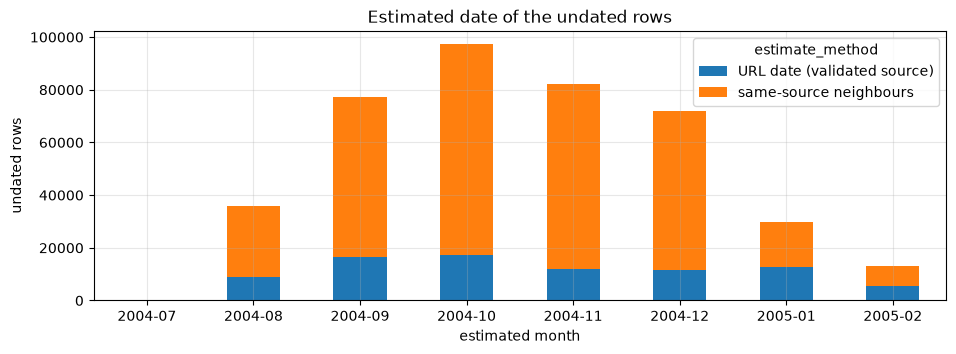

estimated date quantiles: 0.1%: 2004-08-14, 1.0%: 2004-08-19, 50.0%: 2004-10-29, 99.0%: 2005-02-13, 99.9%: 2005-02-17
estimates outside Jul 2004 – Mar 2005: 195 rows


In [16]:
est = df.loc[undated & df['date_estimate'].notna(), ['date_estimate', 'estimate_method']]
month = est['date_estimate'].dt.to_period('M')
in_range = month.between(pd.Period('2004-07', 'M'), pd.Period('2005-03', 'M'))
ax = pd.crosstab(month[in_range], est.loc[in_range, 'estimate_method']).plot.bar(stacked=True, figsize=(11, 3.5), rot=0)
ax.set(xlabel='estimated month', ylabel='undated rows', title='Estimated date of the undated rows')
plt.show()

q = est['date_estimate'].quantile([0.001, 0.01, 0.5, 0.99, 0.999])
print('estimated date quantiles:', ', '.join(f'{k:.1%}: {t:%Y-%m-%d}' for k, t in q.items()))
print(f'estimates outside Jul 2004 – Mar 2005: {(~in_range).sum():,} rows')

**The undated rows are from about mid-August 2004 to mid-February 2005**, the same period as the dated rows of era A.

* About 84k undated rows get a validated URL date. About 323k get a neighbour-based estimate, and about two thirds
  of those are bracketed within a day.
* About 1,400 rows cannot be estimated, because their source has no dated row at all.
* In every 50,000-row window, the median URL date of the undated rows matches the median pubdate of the dated rows
  within a day. The undated rows really belong to the same time as their dated neighbours.
* Neighbour estimates with a bracket wider than 30 days, about 21k rows, are unreliable. Their neighbours are often
  the misplaced rows from 1.7.

### 1.9 Sources in the two eras

In [17]:
src_a, src_b = set(df.loc[in_a, 'source']), set(df.loc[~in_a, 'source'])
print(f'distinct sources: era A {len(src_a):,}, era B {len(src_b):,}, in both {len(src_a & src_b):,}')
print(f"era-B rows from sources that already appear in era A: {df.loc[~in_a, 'source'].isin(src_a).mean():.1%}")
print(f"era-A rows from sources that still appear in era B:   {df.loc[in_a, 'source'].isin(src_b).mean():.1%}")
for era, g in df.groupby('era'):
    cum = g['source'].value_counts(normalize=True).cumsum()
    print(f'era {era}: {(cum < 0.5).sum() + 1} sources give half of the rows, {(cum < 0.9).sum() + 1} give 90%')

pd.concat([df.loc[df['era'].eq(e), 'source'].value_counts(normalize=True).head(12).mul(100).round(1)
             .rename_axis(f'era {e} source').reset_index(name=f'% of era {e}') for e in 'AB'], axis=1)

distinct sources: era A 3,895, era B 131, in both 131
era-B rows from sources that already appear in era A: 100.0%
era-A rows from sources that still appear in era B:   47.9%
era A: 44 sources give half of the rows, 412 give 90%
era B: 20 sources give half of the rows, 67 give 90%


,era A source,% of era A,era B source,% of era B
0,Reuters,3.1,Reuters Top News,4.4
1,Topix.Net Europe,2.6,Yahoo World,3.6
2,Yahoo World,2.6,Yahoo Europe,3.2
3,Yahoo Europe,2.0,Yahoo Entertainment,3.1
4,CNN Top News,2.0,Kataweb Sport,3.0
5,BBC - Front Page,1.8,BBC - Front Page,2.8
6,BBC UK,1.7,BBC UK,2.7
7,Yahoo Sports,1.7,Reuters Business,2.7
8,Reuters Business,1.6,Reuters World,2.7
9,Yahoo Entertainment,1.5,The Register,2.5


Era B is a **curated subset**. All 131 of its sources already appear in era A, but era A has almost 3,900. Era A
has a long tail, with 44 sources making up half its rows; in era B 20 sources do. Half of era A's rows come from
sources that were dropped later.

## Part 2: era B

From here on only **era B** is analysed: rows 594,727 – 1,281,102, May 2006 – Feb 2008. Era A is left out because
its data is not reliable enough:

* 69% of its rows have no date (1.2), and for those the date can only be estimated (1.8).
* Even its dated rows are only roughly in order, with rows from two short periods scattered months away (1.4, 1.7).
* Its `pubdate` is often days away from the date in the article's URL, so it looks like a crawl time rather than a
  publication time (1.5).
* It was collected from about 3,900 uncurated sources, of which era B kept only 131 (1.9).

Era B has a date in every row, is ordered by day, and its dates agree with the URL dates (90–99% within a day). Its
one caveat is the collection outages listed in 1.3.

In [18]:
b = df[df['era'].eq('B')].drop(columns=['era', 'has_date', 'date_estimate', 'estimate_method']).reset_index(drop=True)
print(f"era B: {len(b):,} rows, {b['ts'].min():%Y-%m-%d} – {b['ts'].max():%Y-%m-%d}, "
      f"{b['source'].nunique()} sources, {b['category'].nunique()} categories")

era B: 686,376 rows, 2006-05-19 – 2008-02-20, 131 sources, 13 categories


### 2.1 Column profile

In [19]:
TAG = r'(?i)</?(?:a|p|br|img|font|b|i|u|div|span|table|tr|td|ul|ol|li|strong|em|h[1-6]|hr|blockquote|nobr)\b[^>]*>'
ENTITY = r'&(?:#\d+|[a-zA-Z]+);'
desc = b['description'].fillna('')
text = b['title'] + ' ' + desc

feat = pd.DataFrame({
    'description NULL': b['description'].isna(),
    'description length': desc.str.len(),
    'title length': b['title'].str.len(),
    'URL contains a date': b['url_date'].notna(),
    'Yahoo redirect URL (…/*http://…)': b['url'].str.contains('*http', regex=False),
    'title repeated (extra copies)': b.duplicated('title'),
    'description has a line break': desc.str.contains('\n', regex=False),
    'HTML tags in title': b['title'].str.contains(TAG),
    'HTML tags in description': desc.str.contains(TAG),
    'HTML entities (&#39; &quot; …)': text.str.contains(ENTITY),
    'non-ASCII characters': text.str.contains(r'[^\x00-\x7f]'),
})
profile = feat.mean()
basic = ['description NULL', 'description length', 'title length', 'URL contains a date',
         'Yahoo redirect URL (…/*http://…)', 'title repeated (extra copies)']
pd.Series({k: f'{v:.0f} chars (mean)' if 'length' in k else f'{v:.1%}' for k, v in profile[basic].items()},
          name='era B').to_frame()

,era B
description NULL,1.6%
description length,329 chars (mean)
title length,46 chars (mean)
URL contains a date,58.1%
Yahoo redirect URL (…/*http://…),20.4%
title repeated (extra copies),32.6%


### 2.2 Categories

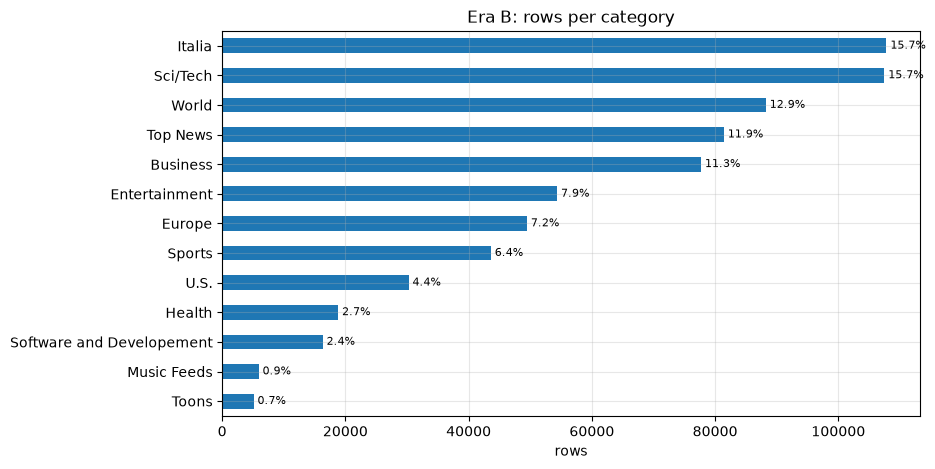

In [20]:
cat = b['category'].value_counts().sort_values()
ax = cat.plot.barh(figsize=(9, 5))
for i, n in enumerate(cat):
    ax.text(n, i, f' {n / len(b):.1%}', va='center', fontsize=8)
ax.set(xlabel='rows', ylabel='', title='Era B: rows per category')
plt.show()

### 2.3 Text formatting

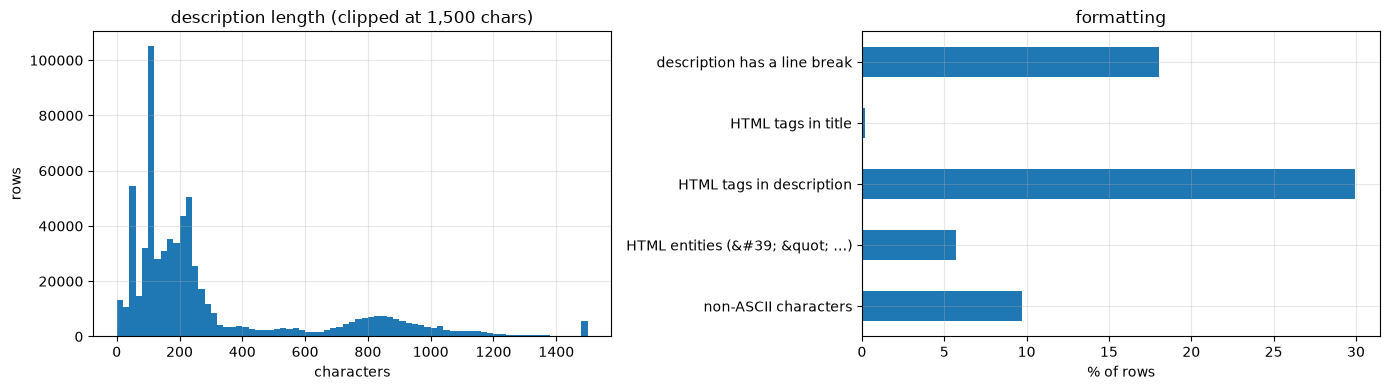

example of HTML in a description (Yahoo Entertainment):
   '<p><a href="http://us.rd.yahoo.com/dailynews/rss/entertainment/*http://news.yahoo.com/s/ap/20060519/ap_en_tv/maury_povich_lawsuit"><img src="http://us.news3.yimg.com/us.i2.yimg.com/p/ap/20060519/capt.1c80312700b347ebb50e8c848c4b10'


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
feat['description length'].clip(upper=1500).plot.hist(bins=75, ax=axes[0])
axes[0].set(title='description length (clipped at 1,500 chars)', xlabel='characters', ylabel='rows')
flags = ['description has a line break', 'HTML tags in title', 'HTML tags in description',
         'HTML entities (&#39; &quot; …)', 'non-ASCII characters']
profile[flags].mul(100).plot.barh(ax=axes[1])
axes[1].set(title='formatting', xlabel='% of rows')
axes[1].invert_yaxis()
fig.tight_layout()
plt.show()

ex = b[feat['HTML tags in description']].iloc[0]
print(f'example of HTML in a description ({ex.source}):\n   {ex.description[:230]!r}')

### 2.4 `image` and `rank`

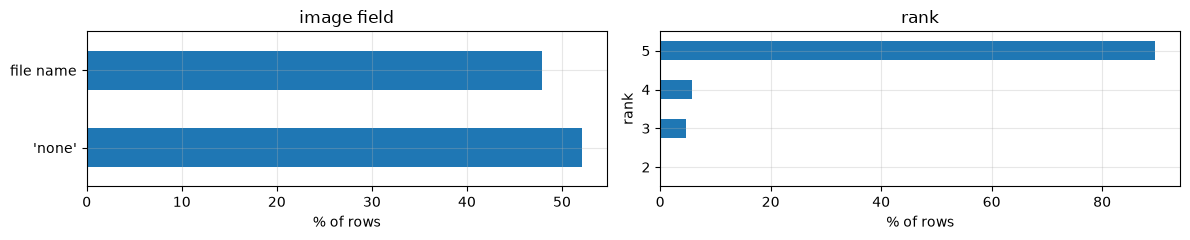

,source,image
15932,Repubblica,http___www.repubblica.it_2006_08_sezioni_esteri_medio-oriente-20_prodi-brindisi_ansa_8...
15936,Repubblica,http___www.repubblica.it_2006_08_sezioni_spettacoli_e_cultura_morto-mahfouz_morto-mahf...
15939,Repubblica,http___www.repubblica.it_2006_08_sezioni_esteri_bimba-ritrovata-austria_parla-amico-ra...


In [22]:
image_kind = pd.Series(np.select([b['image'].eq('none'), b['image'].eq('')], ["'none'", "'' (empty)"], 'file name'),
                       index=b.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 2.5))
image_kind.value_counts(normalize=True).mul(100).plot.barh(ax=axes[0])
axes[0].set(title='image field', xlabel='% of rows', ylabel='')
b['rank'].value_counts(normalize=True).sort_index().mul(100).plot.barh(ax=axes[1])
axes[1].set(title='rank', xlabel='% of rows', ylabel='rank')
fig.tight_layout()
plt.show()

b.loc[image_kind.eq('file name'), ['source', 'image']].head(3)

### 2.5 Summary of era B

| | era B |
|---|---|
| rows | 686,376 (rows 594,727 – 1,281,102) |
| period | 19 May 2006 – 20 Feb 2008 |
| dates | present in every row; ordered by day, shuffled within ~±1.5 h; 90–99% within a day of the URL date |
| coverage | seven outages of 2–10 weeks (plus one of 4 days), about 40% of the period |
| sources | 131; 20 of them give half of the rows |
| categories | 13; *Italia* and *Sci/Tech* are the largest (15.7% each), then *World*, *Top News* and *Business* |
| descriptions | mean 329 chars, in two groups (most under ~300 chars, a second group around 700–1,000); 30% contain raw HTML tags, 18% line breaks, 6% HTML entities; 1.6% NULL |
| titles | mean 46 chars; 32.6% repeat an earlier era-B title |
| `image` | `'none'` 52%, a file name 48%; never empty |
| `rank` | 90% rank 5, the rest mostly 4 and 3 |

For time-based work, use `ts` directly, and account for the outages when counting per day or month. Descriptions
need their HTML removed before any text analysis.